# Beyond RGB: Investigating the Influence of Colour Space Representations on CNN-Based Artistic Style Classification

## Project overview

This project investigates how different colour-space representations influence the classification performance of convolutional neural networks (CNNs).

The classification task involves distinguishing paintings by three artists:

- Claude Monet
- Pablo Picasso
- Vincent van Gogh

The project compares three image representations:

1. RGB
2. HSV
3. Grayscale

## Research question

How does colour-space representation influence the classification performance and generalisation of convolutional neural networks when distinguishing between artistic styles?

## Experimental approach

A custom CNN architecture will be trained and evaluated using identical dataset splits and training configurations across the different colour representations.

Additional experiments will investigate the variability of results across random seeds.

## Frameworks and tools

- Python
- TensorFlow / Keras
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn

## Reproducibility

Dataset splits, random seeds, model configurations, training histories and evaluation metrics will be recorded throughout the experiments.




## 2. Environment setup

This section imports the required libraries and verifies the computational environment.

In [82]:
# Standard libraries
import os
import sys
import json
import hashlib
import random
import time
import shutil

from pathlib import Path

# Data processing
import numpy as np
import pandas as pd

# Image processing
from PIL import Image

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("\nAvailable GPUs:")

for gpu in tf.config.list_physical_devices("GPU"):
    print(gpu)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 2.2.3

Available GPUs:
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


## 3. Project configuration

This section defines the project root, directory structure and experimental configuration.

Centralising these settings makes it easier to maintain consistent experimental conditions.

In [83]:
from google.colab import drive

drive.mount("/content/drive")

# Project root
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/DeepLearning"
)

# Project directories
PATHS = {
    "data_raw": PROJECT_ROOT / "data/raw",
    "data_processed": PROJECT_ROOT / "data/processed",
    "notebooks": PROJECT_ROOT / "notebooks",
    "src": PROJECT_ROOT / "src",
    "models": PROJECT_ROOT / "outputs/models",
    "metrics": PROJECT_ROOT / "outputs/metrics",
    "figures": PROJECT_ROOT / "outputs/figures",
    "tables": PROJECT_ROOT / "outputs/tables",
    "logs": PROJECT_ROOT / "outputs/logs",
    "report_figures": PROJECT_ROOT / "reports/figures",
    "report_tables": PROJECT_ROOT / "reports/tables",
    "report_draft": PROJECT_ROOT / "reports/draft"
}

# Create directories
for path in PATHS.values():
    path.mkdir(parents=True, exist_ok=True)

# Dataset archive
DATA_ARCHIVE = (
    PATHS["data_raw"] / "paintingsSMALL.imscc"
)

# Extracted dataset
DATA_DIR = PATHS["data_processed"] / "paintingsSMALL"

# Dataset configuration
CLASSES = ["monet", "picasso", "vangogh"]

IMAGE_SIZE = (180, 180)
BATCH_SIZE = 16

# Experimental configuration
DEFAULT_SEED = 42
MAX_EPOCHS = 30
LEARNING_RATE = 0.001
EARLY_STOPPING_PATIENCE = 6

print("Project root:", PROJECT_ROOT)
print("Dataset archive exists:", DATA_ARCHIVE.exists())
print("Dataset directory:", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/DeepLearning
Dataset archive exists: True
Dataset directory: /content/drive/MyDrive/DeepLearning/data/processed/paintingsSMALL


In [84]:
environment = {
    "python": sys.version,
    "tensorflow": tf.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "gpu_available": len(
        tf.config.list_physical_devices("GPU")
    ) > 0
}

with open(
    PROJECT_ROOT / "outputs/logs/environment.json",
    "w"
) as file:

    json.dump(environment, file, indent=4)

print(json.dumps(environment, indent=4))

{
    "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
    "tensorflow": "2.21.0",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "gpu_available": true
}


## 4. Project documentation and dependencies

This section establishes the supporting documentation and configuration files for the project.

These files provide an overview of the project, define which files should be excluded from version control, and document the Python dependencies required to run the experiments.

### 4.1 Project documentation — README.md

The README provides an overview of the project, including its research question, dataset, experimental scope, technologies, and directory structure.

It acts as the primary documentation for anyone exploring or reproducing the project.

In [85]:
README_CONTENT = """# Beyond RGB: Artistic Style Classification

## Project overview

This project investigates how colour-space representation influences
the classification performance and generalisation of convolutional
neural networks when distinguishing between artistic styles.

## Research question

How does colour-space representation influence the classification
performance and generalisation of convolutional neural networks
when distinguishing between artistic styles?

## Dataset

The dataset contains paintings from three artistic styles:

- Monet
- Picasso
- Van Gogh

The experiments compare three image representations:

- RGB
- HSV
- Grayscale

## Experimental setup

A consistent CNN architecture and training configuration are used
to compare the colour-space representations.

## Project structure

- `data/`: Raw and processed datasets
- `notebooks/`: Jupyter notebooks for experiments and analysis
- `src/`: Reusable project source code
- `outputs/`: Models, metrics, figures, tables and logs
- `reports/`: Report-ready figures, tables and report drafts

## Reproducibility

Experiments use explicit random seeds and record relevant
environment and training configuration details.

## Technologies

Python, TensorFlow/Keras, NumPy, Pandas, Matplotlib and scikit-learn.
"""

(PROJECT_ROOT / "README.md").write_text(
    README_CONTENT,
    encoding="utf-8"
)

print("README.md created.")

README.md created.


### 4.2 Version control exclusions — .gitignore

The `.gitignore` file specifies which files and directories should not be tracked by Git.

This prevents unnecessary files, local environment configurations, and generated data from being included in version control.

In [86]:
GITIGNORE_CONTENT = """# Python
__pycache__/
*.py[cod]
*.egg-info/
.venv/
venv/

# Jupyter
.ipynb_checkpoints/

# Data
data/raw/
data/processed/

# Model outputs and logs
outputs/models/
outputs/logs/

# Temporary files
.DS_Store
*.tmp
"""

(PROJECT_ROOT / ".gitignore").write_text(
    GITIGNORE_CONTENT,
    encoding="utf-8"
)

print(".gitignore created.")

.gitignore created.


### 4.3 Project dependencies — requirements.txt

The `requirements.txt` file documents the external Python packages used throughout the project.

This provides a starting point for recreating the software environment and supports reproducibility.

In [87]:
REQUIREMENTS_CONTENT = """numpy
pandas
Pillow
matplotlib
seaborn
tensorflow
scikit-learn
"""

(PROJECT_ROOT / "requirements.txt").write_text(
    REQUIREMENTS_CONTENT,
    encoding="utf-8"
)

print("requirements.txt created.")

requirements.txt created.


### 4.4 Verification

Finally, we verify that all three documentation and configuration files have been successfully created in the project root directory.

In [88]:
required_files = [
    "README.md",
    ".gitignore",
    "requirements.txt"
]

for filename in required_files:
    file_path = PROJECT_ROOT / filename

    status = "Created" if file_path.exists() else "Missing"

    print(f"{filename}: {status}")

README.md: Created
.gitignore: Created
requirements.txt: Created


## 5. Project source code

This section introduces the reusable Python modules that form the foundation of the experimental pipeline.

Instead of implementing all functionality directly in notebooks, reusable components are separated into individual modules. This improves maintainability, reduces code duplication, and makes the experiments easier to reproduce.

The source code is organised around the following responsibilities:

- Configuration and project paths
- Dataset loading and preprocessing
- CNN architecture
- Model training
- Model evaluation
- Results visualisation

### 5.1 Central project configuration — config.py

The configuration module defines the project's central settings, including directory paths, dataset classes, image dimensions, training parameters, and random seed.

Centralising these values ensures that all experiments use consistent settings and makes it easier to modify the experimental setup without changing multiple files.

The project root is derived from the location of this module, allowing the code to work independently of the notebook's current working directory.

In [89]:
CONFIG_CONTENT = '''from pathlib import Path

# --------------------------------------------------
# Project directories
# --------------------------------------------------

PROJECT_ROOT = Path(__file__).resolve().parents[1]

DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

DATA_ARCHIVE = DATA_RAW_DIR / "paintingsSMALL.imscc"
DATA_DIR = DATA_PROCESSED_DIR / "paintingsSMALL"

NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"

SRC_DIR = PROJECT_ROOT / "src"

OUTPUTS_DIR = PROJECT_ROOT / "outputs"
MODELS_DIR = OUTPUTS_DIR / "models"
METRICS_DIR = OUTPUTS_DIR / "metrics"
FIGURES_DIR = OUTPUTS_DIR / "figures"
TABLES_DIR = OUTPUTS_DIR / "tables"
LOGS_DIR = OUTPUTS_DIR / "logs"

REPORTS_DIR = PROJECT_ROOT / "reports"
REPORT_FIGURES_DIR = REPORTS_DIR / "figures"
REPORT_TABLES_DIR = REPORTS_DIR / "tables"
REPORT_DRAFT_DIR = REPORTS_DIR / "draft"


# --------------------------------------------------
# Dataset configuration
# --------------------------------------------------

CLASSES = ["monet", "picasso", "vangogh"]

NUM_CLASSES = len(CLASSES)

IMAGE_SIZE = (180, 180)

IMAGE_CHANNELS = 3

BATCH_SIZE = 16


# --------------------------------------------------
# Experiment configuration
# --------------------------------------------------

DEFAULT_SEED = 42

MAX_EPOCHS = 30

LEARNING_RATE = 0.001

EARLY_STOPPING_PATIENCE = 6

REDUCE_LR_PATIENCE = 3

REDUCE_LR_FACTOR = 0.5

MIN_LEARNING_RATE = 0.00001

DROPOUT_RATE = 0.4


# --------------------------------------------------
# Experimental conditions
# --------------------------------------------------

COLOR_SPACES = ["rgb", "hsv", "grayscale"]
'''

config_path = PATHS["src"] / "config.py"

config_path.write_text(CONFIG_CONTENT, encoding="utf-8")

init_path = PATHS["src"] / "__init__.py"

init_path.touch(exist_ok=True)

print("Created:", config_path)
print("Created:", init_path)

Created: /content/drive/MyDrive/DeepLearning/src/config.py
Created: /content/drive/MyDrive/DeepLearning/src/__init__.py


### 5.2 Verification of the configuration module

Before implementing the remaining modules, we verify that the configuration can be imported independently of the notebook variables.

This also confirms that the project paths and experimental settings are correctly defined.

In [90]:
import sys

# Add the project root to Python's module search path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import the configuration module
from src import config

print("Project root:", config.PROJECT_ROOT)
print("Dataset directory:", config.DATA_DIR)
print("Classes:", config.CLASSES)
print("Image size:", config.IMAGE_SIZE)
print("Batch size:", config.BATCH_SIZE)
print("Default seed:", config.DEFAULT_SEED)
print("Maximum epochs:", config.MAX_EPOCHS)
print("Learning rate:", config.LEARNING_RATE)
print("Colour spaces:", config.COLOR_SPACES)

Project root: /content/drive/MyDrive/DeepLearning
Dataset directory: /content/drive/MyDrive/DeepLearning/data/processed/paintingsSMALL
Classes: ['monet', 'picasso', 'vangogh']
Image size: (180, 180)
Batch size: 16
Default seed: 42
Maximum epochs: 30
Learning rate: 0.001
Colour spaces: ['rgb', 'hsv', 'grayscale']


## 6. Dataset loading and preprocessing

This section implements the dataset pipeline used throughout the experiments.

The dataset handling functionality is separated into a reusable Python module to ensure consistent loading and preprocessing across all experimental conditions.

The pipeline covers dataset extraction, directory validation, image loading, normalization, and colour-space transformations.

Three image representations are investigated:

- RGB: Original three-channel colour representation.
- HSV: Hue, saturation, and value representation.
- Grayscale: Single-channel intensity representation, repeated across three channels to maintain compatibility with the same CNN architecture.

The same training, validation, and test splits are retained across all representations to ensure a controlled comparison.

### 6.1 Dataset extraction and validation

Before loading the images, the dataset archive is extracted into the processed data directory.

The extraction step checks whether the dataset has already been extracted to avoid unnecessary repeated processing.

The directory structure is then validated to ensure that all expected classes and dataset splits are available.

In [91]:
DATA_MODULE_CONTENT = '''import zipfile
from pathlib import Path

import tensorflow as tf

from src import config


# --------------------------------------------------
# Dataset extraction
# --------------------------------------------------

def extract_dataset():
    """Extract the dataset archive if it has not already been extracted."""

    archive_path = config.DATA_ARCHIVE
    destination = config.DATA_DIR

    if not archive_path.exists():
        raise FileNotFoundError(
            f"Dataset archive not found: {archive_path}"
        )

    if destination.exists() and any(destination.iterdir()):
        print("Dataset already extracted.")
        return destination

    destination.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(archive_path, "r") as archive:
        archive.extractall(destination)

    print(f"Dataset extracted to: {destination}")

    return destination


# --------------------------------------------------
# Dataset directory validation
# --------------------------------------------------

def get_dataset_root():
    """Locate the directory containing the train, validation and test folders."""

    expected_splits = ["train", "validation", "test"]

    for candidate in [config.DATA_DIR, *config.DATA_DIR.iterdir()]:
        if not candidate.is_dir():
            continue

        if all((candidate / split).is_dir() for split in expected_splits):
            return candidate

    raise FileNotFoundError(
        "Could not locate train, validation and test directories "
        f"inside {config.DATA_DIR}"
    )


def validate_dataset_structure():
    """Check that all expected class directories exist."""

    dataset_root = get_dataset_root()

    for split in ["train", "validation", "test"]:
        split_path = dataset_root / split

        for class_name in config.CLASSES:
            class_path = split_path / class_name

            if not class_path.is_dir():
                raise FileNotFoundError(
                    f"Missing class directory: {class_path}"
                )

    print("Dataset structure validated successfully.")

    return dataset_root


# --------------------------------------------------
# Image loading
# --------------------------------------------------

def load_split(split_name, shuffle=False, seed=None):
    """Load one dataset split using a consistent image configuration."""

    dataset_root = get_dataset_root()
    split_path = dataset_root / split_name

    dataset = tf.keras.utils.image_dataset_from_directory(
        split_path,
        labels="inferred",
        label_mode="categorical",
        class_names=config.CLASSES,
        image_size=config.IMAGE_SIZE,
        batch_size=config.BATCH_SIZE,
        shuffle=shuffle,
        seed=seed,
    )

    return dataset


# --------------------------------------------------
# Colour-space transformations
# --------------------------------------------------

def transform_images(images, color_space):
    """Transform RGB images into the requested colour-space representation."""

    images = tf.cast(images, tf.float32) / 255.0

    if color_space == "rgb":
        return images

    elif color_space == "hsv":
        return tf.image.rgb_to_hsv(images)

    elif color_space == "grayscale":
        grayscale = tf.image.rgb_to_grayscale(images)
        return tf.repeat(grayscale, repeats=3, axis=-1)

    else:
        raise ValueError(
            f"Unsupported colour space: {color_space}"
        )


def prepare_dataset(dataset, color_space):
    """Apply the selected colour-space transformation to a dataset."""

    return dataset.map(
        lambda images, labels: (
            transform_images(images, color_space),
            labels
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    ).prefetch(tf.data.AUTOTUNE)


# --------------------------------------------------
# Complete dataset preparation
# --------------------------------------------------

def load_datasets(color_space, seed=None):
    """Load and prepare training, validation and test datasets."""

    if color_space not in config.COLOR_SPACES:
        raise ValueError(
            f"Unsupported colour space: {color_space}"
        )

    if seed is None:
        seed = config.DEFAULT_SEED

    train_raw = load_split(
        "train",
        shuffle=True,
        seed=seed
    )

    validation_raw = load_split(
        "validation",
        shuffle=False
    )

    test_raw = load_split(
        "test",
        shuffle=False
    )

    train = prepare_dataset(train_raw, color_space)
    validation = prepare_dataset(validation_raw, color_space)
    test = prepare_dataset(test_raw, color_space)

    return train, validation, test
'''

data_path = PATHS["src"] / "data.py"

data_path.write_text(DATA_MODULE_CONTENT, encoding="utf-8")

print("Created:", data_path)

Created: /content/drive/MyDrive/DeepLearning/src/data.py


### 6.2 Dataset extraction and structural validation

We now use the functions defined in the data module to extract the archive and verify the dataset structure.

This step ensures that the expected class folders are available before the images are loaded into TensorFlow.

In [92]:
from src.data import (
    extract_dataset,
    validate_dataset_structure
)

extract_dataset()

dataset_root = validate_dataset_structure()

print("\nDataset root:", dataset_root)

for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")

    for class_name in config.CLASSES:
        class_path = dataset_root / split / class_name

        image_count = sum(
            1 for file in class_path.iterdir()
            if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
        )

        print(f"{class_name}: {image_count} images")

Dataset already extracted.
Dataset structure validated successfully.

Dataset root: /content/drive/MyDrive/DeepLearning/data/processed/paintingsSMALL/paintingsSMALL

TRAIN
monet: 70 images
picasso: 70 images
vangogh: 70 images

VALIDATION
monet: 20 images
picasso: 19 images
vangogh: 20 images

TEST
monet: 10 images
picasso: 10 images
vangogh: 10 images


## 7. Testing the data pipeline

Before implementing the CNN architecture, we verify that the data pipeline produces the expected image representations.

This is an important validation step because all experiments must use consistent image dimensions, labels, and numerical ranges.

The three representations are expected to have the following characteristics:

- RGB: Three colour channels representing red, green, and blue.
- HSV: Three channels representing hue, saturation, and value.
- Grayscale: Three identical channels containing grayscale intensity values.

All images are normalized to the range [0, 1].

### 7.1 Verify image transformations

A batch of validation images is loaded and transformed into each of the three colour-space representations.

We inspect the resulting tensor dimensions, numerical ranges, and labels to confirm that the transformations work as expected.

In [93]:
from src.data import load_split, transform_images

# Load one validation batch without shuffling
validation_raw = load_split("validation", shuffle=False)

images, labels = next(iter(validation_raw))

# Apply all three representations to the same images
rgb_images = transform_images(images, "rgb")
hsv_images = transform_images(images, "hsv")
grayscale_images = transform_images(images, "grayscale")

representations = {
    "RGB": rgb_images,
    "HSV": hsv_images,
    "Grayscale": grayscale_images
}

for name, batch in representations.items():
    print(f"\n{name}")
    print("Shape:", batch.shape)
    print("Minimum:", float(tf.reduce_min(batch)))
    print("Maximum:", float(tf.reduce_max(batch)))
    print("Data type:", batch.dtype)

print("\nLabels shape:", labels.shape)
print("Labels for first image:", labels[0].numpy())

Found 59 files belonging to 3 classes.

RGB
Shape: (16, 180, 180, 3)
Minimum: 0.0
Maximum: 1.0
Data type: <dtype: 'float32'>

HSV
Shape: (16, 180, 180, 3)
Minimum: 0.0
Maximum: 1.0
Data type: <dtype: 'float32'>

Grayscale
Shape: (16, 180, 180, 3)
Minimum: 0.0
Maximum: 0.999005913734436
Data type: <dtype: 'float32'>

Labels shape: (16, 3)
Labels for first image: [1. 0. 0.]


### 7.2 Visual inspection of colour-space representations

Numerical validation is supplemented with a visual inspection of the transformations.

The same image is displayed in its original RGB representation, its HSV channel components, and its grayscale representation.

For HSV, the hue, saturation, and value channels are displayed separately to make the transformation easier to interpret.

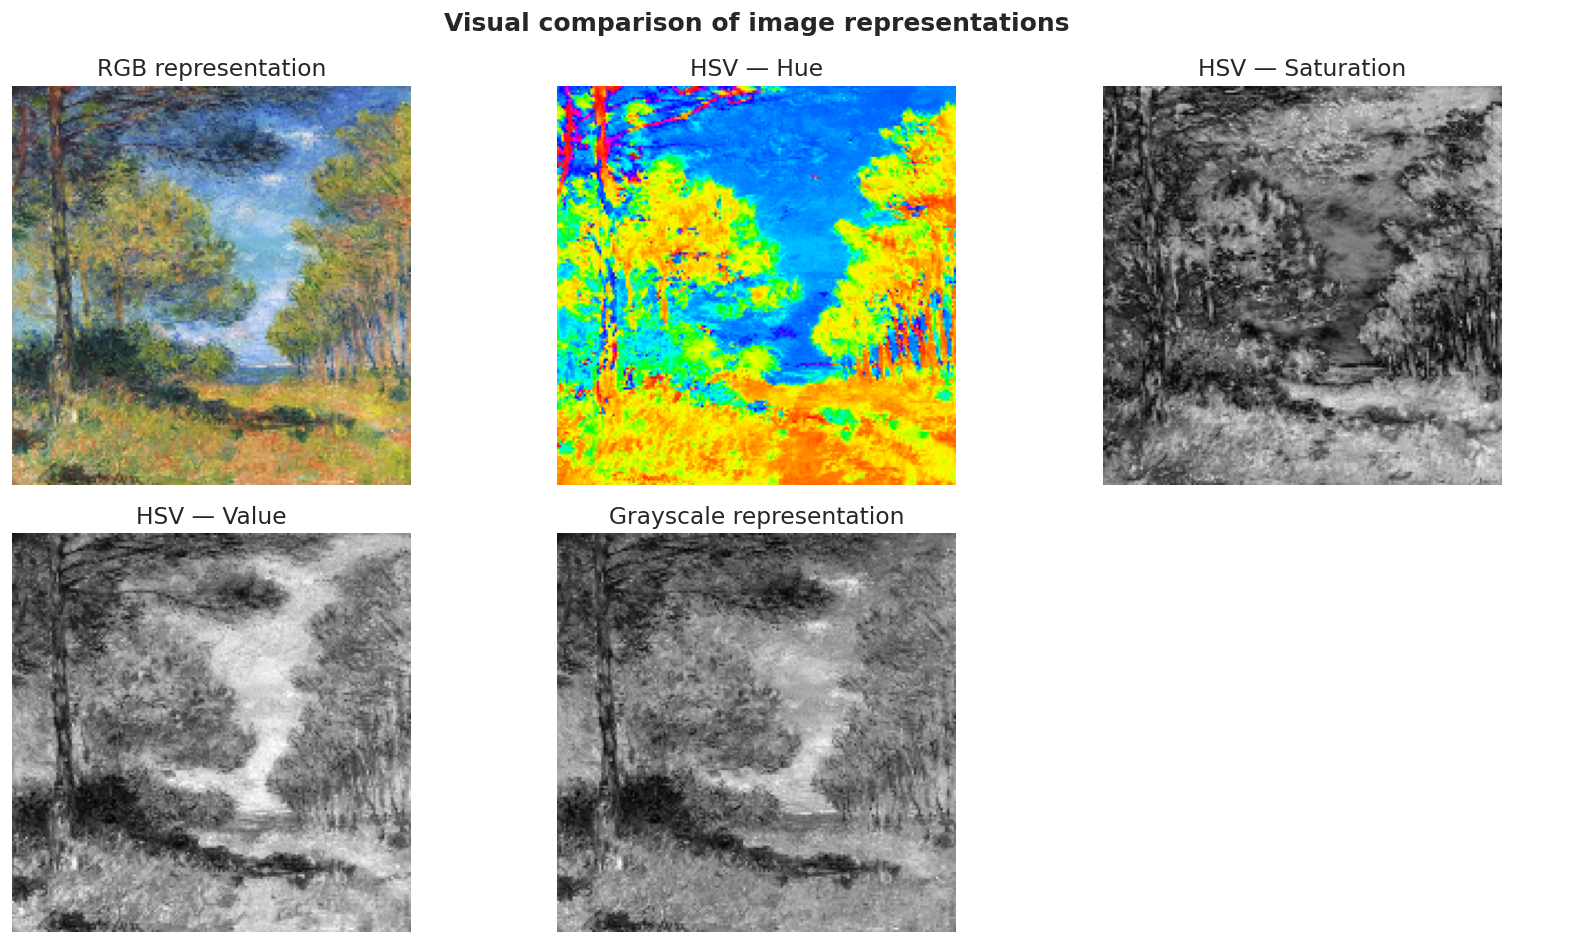

In [94]:
# Select one image from the validation batch
sample_rgb = rgb_images[0].numpy()
sample_hsv = hsv_images[0].numpy()
sample_grayscale = grayscale_images[0].numpy()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# Original RGB
axes[0, 0].imshow(sample_rgb)
axes[0, 0].set_title("RGB representation")

# HSV channels
axes[0, 1].imshow(sample_hsv[:, :, 0], cmap="hsv")
axes[0, 1].set_title("HSV — Hue")

axes[0, 2].imshow(sample_hsv[:, :, 1], cmap="gray")
axes[0, 2].set_title("HSV — Saturation")

axes[1, 0].imshow(sample_hsv[:, :, 2], cmap="gray")
axes[1, 0].set_title("HSV — Value")

# Grayscale
axes[1, 1].imshow(sample_grayscale[:, :, 0], cmap="gray")
axes[1, 1].set_title("Grayscale representation")

axes[1, 2].axis("off")

for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    "Visual comparison of image representations",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 7.3 Verify complete dataset preparation

Finally, we test the complete dataset-loading function for each colour-space representation.

This verifies that the training, validation, and test datasets can all be prepared using the same interface.

The resulting datasets should have compatible image and label dimensions, regardless of the selected representation.

In [95]:
from src.data import load_datasets

for color_space in config.COLOR_SPACES:

    train_ds, validation_ds, test_ds = load_datasets(
        color_space=color_space,
        seed=config.DEFAULT_SEED
    )

    sample_images, sample_labels = next(iter(validation_ds))

    print(f"\n{color_space.upper()}")
    print("Validation image shape:", sample_images.shape)
    print("Validation label shape:", sample_labels.shape)

Found 210 files belonging to 3 classes.
Found 59 files belonging to 3 classes.
Found 30 files belonging to 3 classes.

RGB
Validation image shape: (16, 180, 180, 3)
Validation label shape: (16, 3)
Found 210 files belonging to 3 classes.
Found 59 files belonging to 3 classes.
Found 30 files belonging to 3 classes.

HSV
Validation image shape: (16, 180, 180, 3)
Validation label shape: (16, 3)
Found 210 files belonging to 3 classes.
Found 59 files belonging to 3 classes.
Found 30 files belonging to 3 classes.

GRAYSCALE
Validation image shape: (16, 180, 180, 3)
Validation label shape: (16, 3)


### 7.4 Dataset integrity verification

The extracted dataset is checked for exact duplicate images across the training, validation, and test splits.

This is important because duplicate images across splits can introduce data leakage and lead to overly optimistic evaluation results.

SHA-256 hashes are used to identify byte-identical image files.

In [96]:
import hashlib

def calculate_sha256(file_path):
    """Calculate the SHA-256 hash of a file."""
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


image_records = []

for split in ["train", "validation", "test"]:
    for class_name in config.CLASSES:

        class_dir = dataset_root / split / class_name

        for image_path in class_dir.iterdir():

            if image_path.suffix.lower() not in [
                ".jpg", ".jpeg", ".png"
            ]:
                continue

            image_records.append({
                "split": split,
                "class": class_name,
                "filename": image_path.name,
                "path": str(image_path),
                "sha256": calculate_sha256(image_path)
            })


image_hashes = pd.DataFrame(image_records)

duplicates = image_hashes[
    image_hashes.duplicated("sha256", keep=False)
].sort_values("sha256")

print("Total images:", len(image_hashes))
print("Unique images:", image_hashes["sha256"].nunique())
print("Duplicate image records:", len(duplicates))

if not duplicates.empty:
    display(
        duplicates[["split", "class", "filename", "sha256"]]
    )
else:
    print("No exact duplicates found.")

Total images: 299
Unique images: 299
Duplicate image records: 0
No exact duplicates found.


### 7.5 Resolving duplicate images across dataset splits

The integrity audit identified one exact duplicate image shared between the training and validation sets.

To prevent data leakage, the duplicate validation copy is removed while the training copy is retained.

The dataset is subsequently audited again to confirm that all remaining images are unique across the three splits.


In [99]:
# Exact duplicate identified during the SHA-256 audit

duplicate_validation_image = (
    dataset_root
    / "validation"
    / "picasso"
    / "hb_1990-1.192.jpg"
)

training_image = (
    dataset_root
    / "train"
    / "picasso"
    / "hb_1990.192.jpg"
)

# Verify that the original training image exists.
if not training_image.exists():
    raise FileNotFoundError(
        f"Original training image not found: {training_image}"
    )

# Check whether the validation duplicate still exists.
if duplicate_validation_image.exists():

    # Verify that both files have identical hashes.
    training_hash = calculate_sha256(training_image)
    validation_hash = calculate_sha256(duplicate_validation_image)

    if training_hash == validation_hash:

        # Remove only the validation copy.
        duplicate_validation_image.unlink()

        print("Exact duplicate validation image removed.")

    else:
        raise ValueError(
            "The two images no longer have identical hashes. "
            "No file was deleted."
        )

else:
    print("Validation duplicate has already been removed.")

print("\nDataset verification:")
print("Training image retained:", training_image.exists())
print("Validation duplicate exists:", duplicate_validation_image.exists())

Validation duplicate has already been removed.

Dataset verification:
Training image retained: True
Validation duplicate exists: False


### 7.6 Verification after duplicate removal

The SHA-256 audit is repeated after removing the duplicate validation image.

This verifies that the final dataset contains no exact duplicate images across the training, validation, and test splits.

In [100]:
image_records = []

for split in ["train", "validation", "test"]:
    for class_name in config.CLASSES:

        class_dir = dataset_root / split / class_name

        for image_path in class_dir.iterdir():

            if image_path.suffix.lower() not in [
                ".jpg", ".jpeg", ".png"
            ]:
                continue

            image_records.append({
                "split": split,
                "class": class_name,
                "filename": image_path.name,
                "path": str(image_path),
                "sha256": calculate_sha256(image_path)
            })


image_hashes = pd.DataFrame(image_records)

duplicates = image_hashes[
    image_hashes.duplicated("sha256", keep=False)
]

print("Total images:", len(image_hashes))
print("Unique images:", image_hashes["sha256"].nunique())
print("Duplicate image records:", len(duplicates))

assert len(image_hashes) == 299
assert image_hashes["sha256"].nunique() == 299
assert duplicates.empty

print("\nDataset integrity verified successfully.")

Total images: 299
Unique images: 299
Duplicate image records: 0

Dataset integrity verified successfully.


In [101]:
for split in ["train", "validation", "test"]:

    print(f"\n{split.upper()}")

    for class_name in config.CLASSES:

        class_dir = dataset_root / split / class_name

        image_count = sum(
            1 for file in class_dir.iterdir()
            if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
        )

        print(f"{class_name}: {image_count}")


TRAIN
monet: 70
picasso: 70
vangogh: 70

VALIDATION
monet: 20
picasso: 19
vangogh: 20

TEST
monet: 10
picasso: 10
vangogh: 10


### 7.7 Reusable dataset integrity auditing

To make dataset validation repeatable, the integrity checks are implemented as reusable functions in the data module.

The audit automatically inspects all dataset splits and classes without relying on specific filenames.

It evaluates:

- Image counts per split and class.
- Total number of images.
- Number of unique images based on SHA-256 hashes.
- Exact duplicates within and across dataset splits.
- Missing or unexpected class directories.

The audit returns structured results that can be inspected, exported, and reused throughout the project.

In [102]:
DATA_AUDIT_CODE = '''

# --------------------------------------------------
# Dataset integrity auditing
# --------------------------------------------------

import hashlib
import pandas as pd


def calculate_sha256(file_path):
    """Calculate the SHA-256 hash of an image file."""

    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


def audit_dataset():
    """
    Audit dataset structure, image counts and exact duplicates.

    Returns
    -------
    dict
        Dictionary containing image records, class counts,
        duplicate records and summary statistics.
    """

    dataset_root = get_dataset_root()

    expected_splits = ["train", "validation", "test"]

    image_extensions = {".jpg", ".jpeg", ".png"}

    records = []
    count_records = []

    # Inspect dataset structure and image files
    for split in expected_splits:

        split_path = dataset_root / split

        for class_name in config.CLASSES:

            class_path = split_path / class_name

            if not class_path.is_dir():
                raise FileNotFoundError(
                    f"Missing class directory: {class_path}"
                )

            image_files = sorted(
                file for file in class_path.iterdir()
                if file.is_file()
                and file.suffix.lower() in image_extensions
            )

            count_records.append({
                "split": split,
                "class": class_name,
                "image_count": len(image_files)
            })

            for image_path in image_files:

                records.append({
                    "split": split,
                    "class": class_name,
                    "filename": image_path.name,
                    "path": str(image_path),
                    "sha256": calculate_sha256(image_path)
                })

    # Convert results into DataFrames
    image_records = pd.DataFrame(records)
    class_counts = pd.DataFrame(count_records)

    # Find all exact duplicate files
    duplicates = image_records[
        image_records.duplicated(
            subset="sha256",
            keep=False
        )
    ].sort_values("sha256").reset_index(drop=True)

    # Summary statistics
    total_images = len(image_records)

    unique_images = (
        image_records["sha256"].nunique()
        if total_images > 0 else 0
    )

    duplicate_groups = (
        image_records["sha256"].duplicated().sum()
        if total_images > 0 else 0
    )

    summary = {
        "total_images": total_images,
        "unique_images": unique_images,
        "duplicate_groups": int(duplicate_groups),
        "duplicate_records": len(duplicates),
        "integrity_passed": duplicates.empty
    }

    return {
        "summary": summary,
        "class_counts": class_counts,
        "image_records": image_records,
        "duplicates": duplicates
    }


def print_dataset_audit(results):
    """Display a readable summary of dataset audit results."""

    print("DATASET INTEGRITY AUDIT")
    print("=" * 40)

    print("\\nImage counts:")

    counts = results["class_counts"].pivot(
        index="split",
        columns="class",
        values="image_count"
    )

    counts["Total"] = counts.sum(axis=1)

    print(counts.to_string())

    print("\\nOverall summary:")

    for key, value in results["summary"].items():
        print(f"{key}: {value}")

    if results["summary"]["integrity_passed"]:
        print("\\nNo exact duplicate images found.")
    else:
        print("\\nWARNING: Exact duplicate images detected.")
        print(results["duplicates"][
            ["split", "class", "filename", "sha256"]
        ].to_string(index=False))
'''

with open(PATHS["src"] / "data.py", "a", encoding="utf-8") as file:
    file.write(DATA_AUDIT_CODE)

print("Dataset audit functions added to src/data.py")

Dataset audit functions added to src/data.py


### 7.8 Running the dataset integrity audit

The reusable audit function is now imported and executed.

The resulting summary provides an overview of the dataset composition and identifies any exact duplicate images.

The audit can be repeated whenever the dataset is modified or before a new set of experiments is conducted.

In [103]:
# Import the reusable audit functions
from importlib import reload
import src.data

reload(src.data)

from src.data import audit_dataset, print_dataset_audit

# Run the audit
audit_results = audit_dataset()

# Display results
print_dataset_audit(audit_results)

DATASET INTEGRITY AUDIT

Image counts:
class       monet  picasso  vangogh  Total
split                                     
test           10       10       10     30
train          70       70       70    210
validation     20       19       20     59

Overall summary:
total_images: 299
unique_images: 299
duplicate_groups: 0
duplicate_records: 0
integrity_passed: True

No exact duplicate images found.


In [104]:
# Save the audit results for documentation and reproducibility

audit_results["class_counts"].to_csv(
    config.METRICS_DIR / "dataset_class_counts.csv",
    index=False
)

audit_results["image_records"].to_csv(
    config.METRICS_DIR / "dataset_image_inventory.csv",
    index=False
)

audit_results["duplicates"].to_csv(
    config.METRICS_DIR / "dataset_duplicates.csv",
    index=False
)

print("Dataset audit results exported.")

Dataset audit results exported.


## 8. CNN architecture

This section implements the convolutional neural network used in the classification experiments.

A single CNN architecture is shared across all three colour-space representations to ensure a controlled comparison.

The model consists of:

1. Three convolutional blocks with increasing numbers of filters.
2. Max-pooling layers to progressively reduce spatial dimensions.
3. Global average pooling to aggregate spatial feature information.
4. A fully connected layer for classification features.
5. Dropout regularisation.
6. A softmax output layer for the three artistic style classes.

The architecture is implemented as a reusable Python module in `src/models.py`.

### 8.1 CNN architecture specification

The network uses the following configuration:

| Layer | Configuration |
|---|---|
| Input | 180 × 180 × 3 |
| Convolution 1 | 32 filters, 3 × 3, ReLU |
| Max pooling 1 | 2 × 2 |
| Convolution 2 | 64 filters, 3 × 3, ReLU |
| Max pooling 2 | 2 × 2 |
| Convolution 3 | 128 filters, 3 × 3, ReLU |
| Max pooling 3 | 2 × 2 |
| Global average pooling | — |
| Dense | 128 units, ReLU |
| Dropout | 0.4 |
| Output | 3 units, softmax |

The convolutional layers use same padding to preserve spatial dimensions before pooling.

The model uses global average pooling instead of flattening the feature maps, reducing the number of parameters passed to the dense classification layers.

### 8.2 Implementing the model

The CNN architecture is implemented in a dedicated module.

The `build_cnn()` function creates and returns a model with the same architecture for every experimental condition.

The `compile_cnn()` function configures the optimizer, loss function, and evaluation metric separately from model construction.

In [105]:
MODEL_MODULE_CONTENT = '''import tensorflow as tf

from src import config


# --------------------------------------------------
# CNN architecture
# --------------------------------------------------

def build_cnn():
    """
    Build the shared CNN architecture used in all experiments.

    Returns
    -------
    tf.keras.Model
        Uncompiled CNN classification model.
    """

    model = tf.keras.Sequential([

        tf.keras.layers.Input(
            shape=(
                config.IMAGE_SIZE[0],
                config.IMAGE_SIZE[1],
                config.IMAGE_CHANNELS
            )
        ),

        # Convolutional block 1
        tf.keras.layers.Conv2D(
            32,
            kernel_size=(3, 3),
            activation="relu",
            padding="same"
        ),

        tf.keras.layers.MaxPooling2D(
            pool_size=(2, 2)
        ),

        # Convolutional block 2
        tf.keras.layers.Conv2D(
            64,
            kernel_size=(3, 3),
            activation="relu",
            padding="same"
        ),

        tf.keras.layers.MaxPooling2D(
            pool_size=(2, 2)
        ),

        # Convolutional block 3
        tf.keras.layers.Conv2D(
            128,
            kernel_size=(3, 3),
            activation="relu",
            padding="same"
        ),

        tf.keras.layers.MaxPooling2D(
            pool_size=(2, 2)
        ),

        # Classification head
        tf.keras.layers.GlobalAveragePooling2D(),

        tf.keras.layers.Dense(
            128,
            activation="relu"
        ),

        tf.keras.layers.Dropout(
            config.DROPOUT_RATE
        ),

        tf.keras.layers.Dense(
            config.NUM_CLASSES,
            activation="softmax"
        )
    ])

    return model


# --------------------------------------------------
# Model compilation
# --------------------------------------------------

def compile_cnn(model):
    """
    Compile the CNN using the project's standard configuration.

    Parameters
    ----------
    model : tf.keras.Model
        CNN model to compile.

    Returns
    -------
    tf.keras.Model
        Compiled CNN model.
    """

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=config.LEARNING_RATE
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model
'''

model_path = PATHS["src"] / "models.py"

model_path.write_text(
    MODEL_MODULE_CONTENT,
    encoding="utf-8"
)

print("Created:", model_path)

Created: /content/drive/MyDrive/DeepLearning/src/models.py


### 8.3 Testing the CNN architecture

The model is imported and instantiated to verify that the architecture is constructed correctly.

The model summary is inspected to confirm the layer configuration, output dimensions, and number of trainable parameters.

The model is then compiled using the predefined experimental configuration.

In [106]:
import importlib
import src.models

importlib.reload(src.models)

from src.models import build_cnn, compile_cnn

# Build and compile the model
cnn_model = build_cnn()
cnn_model = compile_cnn(cnn_model)

# Display architecture
cnn_model.summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_45 (Conv2D)              │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_45 (MaxPooling2D) │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_46 (Conv2D)              │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_46 (MaxPooling2D) │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_47 (Conv2D)              │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_47 (MaxPooling2D) │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_15     │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

### 8.4 Verifying model consistency

Since all experimental conditions use the same architecture, we verify that independently created models have identical layer configurations and parameter counts.

This helps ensure that the colour-space representation is the primary experimental variable rather than differences in model architecture.

In [107]:
# Compare architecture structure without relying on generated layer names

types_a = [layer.__class__.__name__ for layer in model_a.layers]
types_b = [layer.__class__.__name__ for layer in model_b.layers]

shapes_a = [tuple(layer.output.shape) for layer in model_a.layers]
shapes_b = [tuple(layer.output.shape) for layer in model_b.layers]

assert types_a == types_b
assert shapes_a == shapes_b
assert model_a.count_params() == model_b.count_params()
assert model_a.input_shape == model_b.input_shape
assert model_a.output_shape == model_b.output_shape

print("Model architecture consistency verified.")
print("Input shape:", model_a.input_shape)
print("Output shape:", model_a.output_shape)
print("Total parameters:", model_a.count_params())
print("Number of layers:", len(model_a.layers))

Model architecture consistency verified.
Input shape: (None, 180, 180, 3)
Output shape: (None, 3)
Total parameters: 110147
Number of layers: 10


## 9. Model training pipeline

This section implements a reusable training pipeline for the CNN classification experiments.

The training functionality is separated from the model architecture and dataset preparation to ensure that the same training procedure is applied across all experimental conditions.

The pipeline includes:

- Random seed configuration.
- Model initialization and compilation.
- Early stopping.
- Learning-rate reduction.
- Model checkpointing.
- Training duration measurement.
- Training history export.

The training function accepts a colour-space representation and random seed, allowing the same implementation to be reused across baseline and repeatability experiments.

### 9.1 Reproducibility and random seed configuration

Random seeds are configured to improve the reproducibility of the experiments.

The configuration covers Python, NumPy, and TensorFlow random number generators.

TensorFlow operations are also configured to use deterministic execution where supported.

In [108]:
TRAINING_MODULE_CONTENT = '''import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

from src import config
from src.models import build_cnn, compile_cnn


# --------------------------------------------------
# Reproducibility
# --------------------------------------------------

def set_random_seed(seed=None):
    """Set random seeds across Python, NumPy and TensorFlow."""

    if seed is None:
        seed = config.DEFAULT_SEED

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

    return seed


# --------------------------------------------------
# Training callbacks
# --------------------------------------------------

def create_training_callbacks(color_space, seed):
    """Create callbacks used during model training."""

    checkpoint_path = (
        config.MODELS_DIR /
        f"{color_space}_seed{seed}.keras"
    )

    callbacks = [

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=config.EARLY_STOPPING_PATIENCE,
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=config.REDUCE_LR_FACTOR,
            patience=config.REDUCE_LR_PATIENCE,
            min_lr=config.MIN_LEARNING_RATE,
            verbose=1
        ),

        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]

    return callbacks, checkpoint_path


# --------------------------------------------------
# Model training
# --------------------------------------------------

def train_model(
    train_dataset,
    validation_dataset,
    color_space,
    seed=None,
    epochs=None
):
    """
    Train the CNN using the project's standard configuration.

    Parameters
    ----------
    train_dataset : tf.data.Dataset
        Training dataset.
    validation_dataset : tf.data.Dataset
        Validation dataset.
    color_space : str
        Image representation used in the experiment.
    seed : int, optional
        Random seed.
    epochs : int, optional
        Maximum number of training epochs.

    Returns
    -------
    tuple
        Trained model, training history, and metadata.
    """

    if color_space not in config.COLOR_SPACES:
        raise ValueError(
            f"Unsupported colour space: {color_space}"
        )

    if seed is None:
        seed = config.DEFAULT_SEED

    if epochs is None:
        epochs = config.MAX_EPOCHS

    set_random_seed(seed)

    model = compile_cnn(build_cnn())

    callbacks, checkpoint_path = create_training_callbacks(
        color_space,
        seed
    )

    start_time = time.perf_counter()

    history = model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=epochs,
        callbacks=callbacks,
        verbose=1
    )

    training_time = time.perf_counter() - start_time

    # Ensure the best checkpoint weights are used
    if checkpoint_path.exists():
        model = tf.keras.models.load_model(checkpoint_path)

    history_df = pd.DataFrame(history.history)

    history_path = (
        config.METRICS_DIR /
        f"{color_space}_seed{seed}_history.csv"
    )

    history_df.to_csv(history_path, index=False)

    metadata = {
        "color_space": color_space,
        "seed": seed,
        "epochs_completed": len(history.history["loss"]),
        "best_epoch": int(
            np.argmin(history.history["val_loss"]) + 1
        ),
        "training_time_seconds": training_time,
        "model_path": str(checkpoint_path),
        "history_path": str(history_path),
        "parameter_count": model.count_params()
    }

    return model, history, metadata
'''

training_path = PATHS["src"] / "training.py"

training_path.write_text(
    TRAINING_MODULE_CONTENT,
    encoding="utf-8"
)

print("Created:", training_path)

Created: /content/drive/MyDrive/DeepLearning/src/training.py


### 9.2 Training pipeline verification

The training module is imported to verify that its functions can be accessed independently of the notebook.

The random seed configuration and callback construction are tested before conducting a complete training run.

In [109]:
import importlib
import src.training

importlib.reload(src.training)

from src.training import (
    set_random_seed,
    create_training_callbacks,
    train_model
)

# Verify random seed configuration
seed = set_random_seed(config.DEFAULT_SEED)

print("Random seed configured:", seed)

# Verify callback creation
callbacks, checkpoint_path = create_training_callbacks(
    color_space="rgb",
    seed=config.DEFAULT_SEED
)

print("\nConfigured callbacks:")

for callback in callbacks:
    print(type(callback).__name__)

print("\nCheckpoint path:", checkpoint_path)

Random seed configured: 42

Configured callbacks:
EarlyStopping
ReduceLROnPlateau
ModelCheckpoint

Checkpoint path: /content/drive/MyDrive/DeepLearning/outputs/models/rgb_seed42.keras


### 9.3 First controlled training run

Before running the complete baseline experiments, a training run is conducted using the RGB representation and the default random seed.

This verifies that the training pipeline integrates correctly with the dataset preparation and CNN architecture modules.

The experiment uses the predefined training configuration, including early stopping and learning-rate reduction.

The resulting model, training history, and metadata are saved for subsequent evaluation.

In [110]:
from src.data import load_datasets

# Prepare RGB datasets
train_ds, validation_ds, test_ds = load_datasets(
    color_space="rgb",
    seed=config.DEFAULT_SEED
)

# Train the model
rgb_model, rgb_history, rgb_metadata = train_model(
    train_dataset=train_ds,
    validation_dataset=validation_ds,
    color_space="rgb",
    seed=config.DEFAULT_SEED
)

print("\nTraining metadata:")

for key, value in rgb_metadata.items():
    print(f"{key}: {value}")

Found 210 files belonging to 3 classes.
Found 59 files belonging to 3 classes.
Found 30 files belonging to 3 classes.
Epoch 1/30


13/14 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step - accuracy: 0.2688 - loss: 1.1006
Epoch 1: val_loss improved from None to 1.06527, saving model to /content/drive/MyDrive/DeepLearning/outputs/models/rgb_seed42.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DeepLearning/outputs/models/rgb_seed42.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 259ms/step - accuracy: 0.3286 - loss: 1.0899 - val_accuracy: 0.3220 - val_loss: 1.0653 - learning_rate: 0.0010
Epoch 2/30
13/14 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.3393 - loss: 1.0707
Epoch 2: val_loss improved from 1.06527 to 0.97899, saving model to /content/drive/MyDrive/DeepLearning/outputs/models/rgb_seed42.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DeepLearning/outputs/models/rgb_seed42.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 152ms/step - accuracy: 0.3810 - loss: 1.0499 - val_accuracy: 0.5932 - val_loss: 0.9790 - learning_rate: 0.0010
Epoch 3/30
13/14 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.5056 - loss: 1.0

### 9.4 Training history inspection

The training history is inspected to understand how the model develops during training.

Training and validation accuracy and loss are examined to identify convergence behaviour and potential differences between training and validation performance.

The history is also retained as a CSV file for subsequent analysis and visualisation.

In [111]:
history_df = pd.DataFrame(rgb_history.history)

display(history_df.tail())

print("\nBest validation accuracy:",
      history_df["val_accuracy"].max())

print("Best validation loss:",
      history_df["val_loss"].min())

print("Completed epochs:",
      len(history_df))

,accuracy,loss,val_accuracy,val_loss,learning_rate
25,0.809524,0.521748,0.864407,0.435862,0.00025
26,0.790476,0.511104,0.864407,0.434674,0.00025
27,0.723810,0.524364,0.796610,0.426809,0.00025
28,0.766667,0.549098,0.847458,0.463800,0.00025
29,0.714286,0.551235,0.847458,0.434201,0.00025



Best validation accuracy: 0.8644067645072937
Best validation loss: 0.4268088638782501
Completed epochs: 30


### 9.5 Verification of saved training artifacts

The training outputs are verified to ensure that the trained model and training history have been successfully saved.

These artifacts will be used in subsequent evaluation and analysis stages.

In [112]:
model_file = config.MODELS_DIR / "rgb_seed42.keras"

history_file = config.METRICS_DIR / "rgb_seed42_history.csv"

print("Model exists:", model_file.exists())
print("History exists:", history_file.exists())

print("\nModel size (MB):",
      round(model_file.stat().st_size / (1024 ** 2), 2))

print("History size (KB):",
      round(history_file.stat().st_size / 1024, 2))

Model exists: True
History exists: True

Model size (MB): 1.31
History size (KB): 2.91


## 10. Model evaluation

This section implements the evaluation procedures used to assess the classification performance of the trained CNN models.

Evaluation is performed using the held-out test dataset, which is kept separate from model training and validation.

The following metrics are used:

- Accuracy: Overall proportion of correctly classified images.
- Precision: Proportion of positive predictions that are correct.
- Recall: Proportion of actual class instances correctly identified.
- F1-score: Harmonic mean of precision and recall.
- Confusion matrix: Distribution of correct and incorrect predictions across the classes.

Macro-averaged precision, recall, and F1-score are used to give equal weight to each artistic style.

The evaluation functionality is implemented in `src/evaluation.py` to ensure consistent assessment across experimental conditions.

### 10.1 Implementing evaluation functions

The evaluation module contains reusable functions for generating predictions, calculating classification metrics, and producing confusion matrices.

The evaluation function returns structured results that can be saved and compared across experiments.

In [113]:
EVALUATION_MODULE_CONTENT = '''import json
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

from src import config


# --------------------------------------------------
# Model predictions
# --------------------------------------------------

def predict_dataset(model, dataset):
    """Generate predictions and collect true labels."""

    true_labels = []
    predicted_probabilities = []

    for images, labels in dataset:

        probabilities = model.predict(
            images,
            verbose=0
        )

        true_labels.extend(
            np.argmax(labels.numpy(), axis=1)
        )

        predicted_probabilities.extend(probabilities)

    true_labels = np.asarray(true_labels)
    predicted_probabilities = np.asarray(
        predicted_probabilities
    )

    predicted_labels = np.argmax(
        predicted_probabilities,
        axis=1
    )

    return (
        true_labels,
        predicted_labels,
        predicted_probabilities
    )


# --------------------------------------------------
# Classification metrics
# --------------------------------------------------

def calculate_metrics(
    true_labels,
    predicted_labels,
    color_space,
    seed
):
    """Calculate overall and per-class classification metrics."""

    accuracy = accuracy_score(
        true_labels,
        predicted_labels
    )

    precision = precision_score(
        true_labels,
        predicted_labels,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        true_labels,
        predicted_labels,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        true_labels,
        predicted_labels,
        average="macro",
        zero_division=0
    )

    report = classification_report(
        true_labels,
        predicted_labels,
        labels=range(config.NUM_CLASSES),
        target_names=config.CLASSES,
        output_dict=True,
        zero_division=0
    )

    class_report = pd.DataFrame(report).transpose()

    summary = {
        "color_space": color_space,
        "seed": seed,
        "accuracy": accuracy,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1
    }

    return summary, class_report


# --------------------------------------------------
# Confusion matrix
# --------------------------------------------------

def calculate_confusion_matrix(
    true_labels,
    predicted_labels
):
    """Generate confusion matrix using the configured class order."""

    return confusion_matrix(
        true_labels,
        predicted_labels,
        labels=range(config.NUM_CLASSES)
    )


# --------------------------------------------------
# Complete model evaluation
# --------------------------------------------------

def evaluate_model(
    model,
    test_dataset,
    color_space,
    seed=None
):
    """Evaluate a trained model on the test dataset."""

    if color_space not in config.COLOR_SPACES:
        raise ValueError(
            f"Unsupported colour space: {color_space}"
        )

    if seed is None:
        seed = config.DEFAULT_SEED

    test_loss, test_accuracy = model.evaluate(
        test_dataset,
        verbose=0
    )

    true_labels, predicted_labels, probabilities = (
        predict_dataset(model, test_dataset)
    )

    summary, class_report = calculate_metrics(
        true_labels,
        predicted_labels,
        color_space,
        seed
    )

    summary["test_loss"] = float(test_loss)
    summary["test_accuracy"] = float(test_accuracy)

    matrix = calculate_confusion_matrix(
        true_labels,
        predicted_labels
    )

    return {
        "summary": summary,
        "class_report": class_report,
        "confusion_matrix": matrix,
        "true_labels": true_labels,
        "predicted_labels": predicted_labels,
        "predicted_probabilities": probabilities
    }


# --------------------------------------------------
# Saving evaluation results
# --------------------------------------------------

def save_evaluation_results(results, color_space, seed):
    """Save evaluation metrics and predictions."""

    summary_path = (
        config.METRICS_DIR /
        f"{color_space}_seed{seed}_evaluation.json"
    )

    report_path = (
        config.METRICS_DIR /
        f"{color_space}_seed{seed}_classification_report.csv"
    )

    confusion_path = (
        config.METRICS_DIR /
        f"{color_space}_seed{seed}_confusion_matrix.csv"
    )

    predictions_path = (
        config.METRICS_DIR /
        f"{color_space}_seed{seed}_predictions.csv"
    )

    with open(summary_path, "w", encoding="utf-8") as file:
        json.dump(results["summary"], file, indent=4)

    results["class_report"].to_csv(report_path)

    confusion_df = pd.DataFrame(
        results["confusion_matrix"],
        index=config.CLASSES,
        columns=config.CLASSES
    )

    confusion_df.to_csv(confusion_path)

    predictions_df = pd.DataFrame({
        "true_label": [
            config.CLASSES[i]
            for i in results["true_labels"]
        ],
        "predicted_label": [
            config.CLASSES[i]
            for i in results["predicted_labels"]
        ]
    })

    predictions_df.to_csv(
        predictions_path,
        index=False
    )

    return {
        "summary": summary_path,
        "classification_report": report_path,
        "confusion_matrix": confusion_path,
        "predictions": predictions_path
    }
'''

evaluation_path = PATHS["src"] / "evaluation.py"

evaluation_path.write_text(
    EVALUATION_MODULE_CONTENT,
    encoding="utf-8"
)

print("Created:", evaluation_path)

Created: /content/drive/MyDrive/DeepLearning/src/evaluation.py


### 10.2 Import and verify the evaluation module

The evaluation module is imported to verify that its functions are accessible and that the module can be used independently of the notebook.

In [114]:
import importlib
import src.evaluation

importlib.reload(src.evaluation)

from src.evaluation import (
    predict_dataset,
    calculate_metrics,
    calculate_confusion_matrix,
    evaluate_model,
    save_evaluation_results
)

print("Evaluation module imported successfully.")

Evaluation module imported successfully.


### 10.3 Evaluating the RGB model

The RGB model from the training pipeline verification is evaluated using the held-out test dataset.

The test metrics, classification report, and confusion matrix are generated and saved for subsequent analysis.

This evaluation serves as a functional test of the evaluation pipeline. The definitive baseline comparison will be conducted after all three colour-space models have been trained using the finalized pipeline.

In [115]:
from src.data import load_datasets

# Load the test dataset
_, _, rgb_test_ds = load_datasets(
    color_space="rgb",
    seed=config.DEFAULT_SEED
)

# Evaluate the trained model
rgb_evaluation = evaluate_model(
    model=rgb_model,
    test_dataset=rgb_test_ds,
    color_space="rgb",
    seed=config.DEFAULT_SEED
)

# Display overall metrics
print("RGB TEST RESULTS")
print("=" * 40)

for metric, value in rgb_evaluation["summary"].items():
    print(f"{metric}: {value:.4f}" if isinstance(value, float)
          else f"{metric}: {value}")

print("\nCLASSIFICATION REPORT")

display(rgb_evaluation["class_report"])

print("\nCONFUSION MATRIX")

display(
    pd.DataFrame(
        rgb_evaluation["confusion_matrix"],
        index=config.CLASSES,
        columns=config.CLASSES
    )
)

Found 210 files belonging to 3 classes.
Found 59 files belonging to 3 classes.
Found 30 files belonging to 3 classes.
RGB TEST RESULTS
color_space: rgb
seed: 42
accuracy: 0.8333
macro_precision: 0.8424
macro_recall: 0.8333
macro_f1: 0.8364
test_loss: 0.4461
test_accuracy: 0.8333

CLASSIFICATION REPORT


,precision,recall,f1-score,support
monet,0.800000,0.800000,0.800000,10.000000
picasso,1.000000,0.900000,0.947368,10.000000
vangogh,0.727273,0.800000,0.761905,10.000000
accuracy,0.833333,0.833333,0.833333,0.833333
macro avg,0.842424,0.833333,0.836424,30.000000
weighted avg,0.842424,0.833333,0.836424,30.000000



CONFUSION MATRIX


,monet,picasso,vangogh
monet,8,0,2
picasso,0,9,1
vangogh,2,0,8


### 10.4 Saving evaluation results

The evaluation results are exported in structured formats to support subsequent comparison and visualisation.

The exported files include:

- Overall evaluation metrics in JSON format.
- Per-class classification metrics in CSV format.
- Confusion matrix in CSV format.
- Individual predictions in CSV format.

In [116]:
saved_evaluation_files = save_evaluation_results(
    results=rgb_evaluation,
    color_space="rgb",
    seed=config.DEFAULT_SEED
)

print("Saved evaluation files:")

for name, path in saved_evaluation_files.items():
    print(f"{name}: {path}")

Saved evaluation files:
summary: /content/drive/MyDrive/DeepLearning/outputs/metrics/rgb_seed42_evaluation.json
classification_report: /content/drive/MyDrive/DeepLearning/outputs/metrics/rgb_seed42_classification_report.csv
confusion_matrix: /content/drive/MyDrive/DeepLearning/outputs/metrics/rgb_seed42_confusion_matrix.csv
predictions: /content/drive/MyDrive/DeepLearning/outputs/metrics/rgb_seed42_predictions.csv


### 10.5 Initial RGB evaluation observations

The initial RGB model achieved a test accuracy of 83.33% and a macro F1-score of 0.8364.

Picasso achieved the highest class-specific F1-score (0.9474), while Van Gogh achieved the lowest (0.7619).

The confusion matrix indicates that most classification errors occurred between Monet and Van Gogh.

These results serve as an initial verification of the evaluation pipeline. They are not yet used as the definitive baseline for comparing colour-space representations.

## 11. Visualisation

This module contains reusable functions for visualising model training,
evaluation results and comparisons between colour-space experiments.

All figures are saved in both PNG (300 DPI) and PDF formats to support
exploratory analysis and inclusion in the final report.

In [117]:
VISUALIZATION_MODULE_CONTENT = '''
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

from src import config


def set_publication_style():
    """Apply consistent styling to all project figures."""

    sns.set_theme(
        style="whitegrid",
        context="paper",
        font_scale=1.2
    )

    plt.rcParams.update({
        "figure.figsize": (8, 5),
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "font.family": "sans-serif",
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "legend.fontsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "figure.autolayout": True
    })


def save_figure(fig, filename, save=True):
    """Save a figure as high-resolution PNG and PDF."""

    if not save:
        return

    config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    config.REPORT_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

    png_path = config.FIGURES_DIR / f"{filename}.png"
    pdf_path = config.FIGURES_DIR / f"{filename}.pdf"

    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")

    report_png = config.REPORT_FIGURES_DIR / f"{filename}.png"
    report_pdf = config.REPORT_FIGURES_DIR / f"{filename}.pdf"

    fig.savefig(report_png, dpi=300, bbox_inches="tight")
    fig.savefig(report_pdf, bbox_inches="tight")

    print(f"Saved: {png_path}")
    print(f"Saved: {pdf_path}")


def plot_training_history(history, color_space, seed, save=True):
    """Plot training and validation accuracy and loss.

    Accepts either a Keras History object or a pandas DataFrame
    loaded from a previously saved training history CSV.
    """

    set_publication_style()

    # Support both Keras History objects and DataFrames.
    if hasattr(history, "history"):
        history_data = history.history
    else:
        history_data = history.to_dict(orient="list")

    epochs = range(1, len(history_data["accuracy"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    # Accuracy
    axes[0].plot(
        epochs,
        history_data["accuracy"],
        label="Training accuracy"
    )
    axes[0].plot(
        epochs,
        history_data["val_accuracy"],
        label="Validation accuracy"
    )

    axes[0].set_title("Model accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    # Loss
    axes[1].plot(
        epochs,
        history_data["loss"],
        label="Training loss"
    )
    axes[1].plot(
        epochs,
        history_data["val_loss"],
        label="Validation loss"
    )

    axes[1].set_title("Model loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    fig.suptitle(
        f"Training history: {color_space.upper()} (seed {seed})",
        fontsize=15
    )

    save_figure(
        fig,
        f"training_curves_{color_space}_seed{seed}",
        save
    )

    plt.show()
    plt.close(fig)


def plot_confusion_matrix(
    confusion_matrix,
    color_space,
    seed,
    normalize=False,
    save=True
):
    """Plot a confusion matrix with optional row-wise normalization."""

    set_publication_style()

    matrix = np.array(confusion_matrix)

    if normalize:
        row_sums = matrix.sum(axis=1, keepdims=True)

        matrix = np.divide(
            matrix,
            row_sums,
            out=np.zeros_like(matrix, dtype=float),
            where=row_sums != 0
        )

        annotations = np.array([
            [f"{value:.1%}" for value in row]
            for row in matrix
        ])

        value_format = ""
        title_suffix = " (Normalized)"

    else:
        annotations = True
        value_format = "d"
        title_suffix = ""

    fig, ax = plt.subplots(figsize=(6, 5))

    sns.heatmap(
        matrix,
        annot=annotations,
        fmt=value_format,
        cmap="Blues",
        xticklabels=config.CLASSES,
        yticklabels=config.CLASSES,
        cbar=True,
        ax=ax
    )

    ax.set_title(
        f"{color_space.upper()} Confusion Matrix{title_suffix}"
    )
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")

    save_figure(
        fig,
        f"confusion_matrix_{color_space}_seed{seed}"
        + ("_normalized" if normalize else ""),
        save
    )

    plt.show()
    plt.close(fig)


def plot_class_metrics(class_report, color_space, seed, save=True):
    """Compare precision, recall and F1-score across classes."""

    set_publication_style()

    metrics = class_report.copy()

    # Exclude aggregate rows from the class-level comparison.
    metrics = metrics.loc[
        metrics.index.isin(config.CLASSES),
        ["precision", "recall", "f1-score"]
    ]

    metrics = metrics.rename(columns={
        "precision": "Precision",
        "recall": "Recall",
        "f1-score": "F1-score"
    })

    fig, ax = plt.subplots(figsize=(9, 5))

    metrics.plot(
        kind="bar",
        ax=ax,
        width=0.75
    )

    ax.set_title(
        f"Per-class performance: {color_space.upper()}"
    )
    ax.set_xlabel("Artistic style")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)
    ax.legend(title="Metric")
    ax.tick_params(axis="x", rotation=0)

    save_figure(
        fig,
        f"class_metrics_{color_space}_seed{seed}",
        save
    )

    plt.show()
    plt.close(fig)
'''

visualization_path = PROJECT_ROOT / "src" / "visualization.py"
visualization_path.write_text(VISUALIZATION_MODULE_CONTENT)

print(f"Created: {visualization_path}")

Created: /content/drive/MyDrive/DeepLearning/src/visualization.py


### 11.1 Import and verify the visualisation module

Import the newly created module and verify that all visualisation
functions are available.

In [118]:
import importlib
from src import visualization

importlib.reload(visualization)

print("Available visualisation functions:")

print([
    name for name in dir(visualization)
    if name.startswith("plot_")
])

Available visualisation functions:
['plot_class_metrics', 'plot_confusion_matrix', 'plot_training_history']


### 11.2 Load RGB training history

Retrieve the training history from the previously completed RGB experiment.

The saved CSV file contains the training and validation metrics for
each epoch, allowing the learning curves to be reconstructed without
retraining the model.

In [119]:
import pandas as pd

rgb_history_path = config.METRICS_DIR / "rgb_seed42_history.csv"

rgb_history_df = pd.read_csv(rgb_history_path)

print(rgb_history_df.head())

print("\nAvailable columns:")
print(rgb_history_df.columns.tolist())

   accuracy      loss  val_accuracy  val_loss  learning_rate
0  0.328571  1.089916      0.322034  1.065268          0.001
1  0.380952  1.049918      0.593220  0.978988          0.001
2  0.528571  0.980235      0.610169  0.860494          0.001
3  0.552381  0.933065      0.593220  0.753971          0.001
4  0.609524  0.866913      0.593220  0.750301          0.001

Available columns:
['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate']


### 11.3 RGB training history

The training curves show how the model's performance changes over
successive epochs.

Comparing training and validation curves helps identify learning
behaviour, convergence and potential overfitting.

Training accuracy and validation accuracy describe classification
performance, while training loss and validation loss describe the
model's optimisation objective.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/training_curves_rgb_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/training_curves_rgb_seed42.pdf


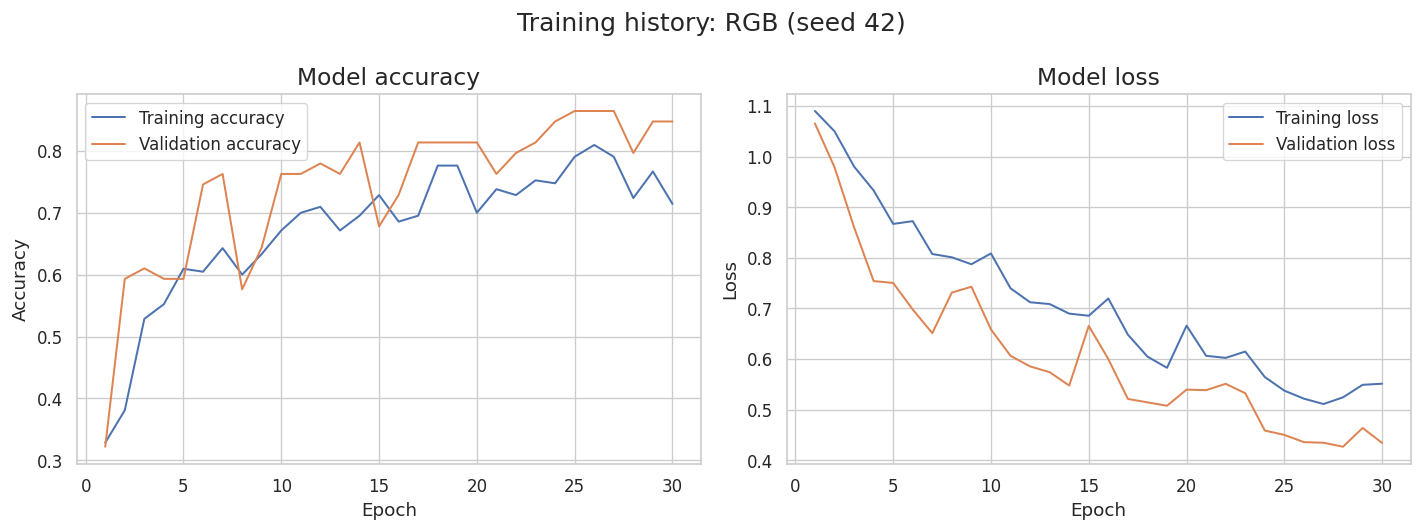

In [120]:
visualization.plot_training_history(
    history=rgb_history_df,
    color_space="rgb",
    seed=42
)

### 11.4 Load RGB model and recreate evaluation results

Load the previously trained RGB model from its saved checkpoint.

The model is evaluated on the test dataset to recreate the evaluation
results required for the subsequent visualisations.

Since the trained model is loaded from disk, no additional training
is performed.

In [121]:
import tensorflow as tf
import importlib

from src import evaluation, data

# Reload the modules to ensure the latest implementations are used.
importlib.reload(data)
importlib.reload(evaluation)

# Load the saved RGB model.
rgb_model_path = config.MODELS_DIR / "rgb_seed42.keras"

rgb_model = tf.keras.models.load_model(rgb_model_path)

# Load the RGB test dataset.
_, _, rgb_test_dataset = data.load_datasets(
    color_space="rgb",
    seed=42
)

# Recreate the evaluation results.
rgb_results = evaluation.evaluate_model(
    model=rgb_model,
    test_dataset=rgb_test_dataset,
    color_space="rgb",
    seed=42
)

# Save the recreated evaluation results.
evaluation.save_evaluation_results(
    results=rgb_results,
    color_space="rgb",
    seed=42
)

print("\nRGB evaluation results recreated successfully.")
print(rgb_results["summary"])

Found 210 files belonging to 3 classes.
Found 59 files belonging to 3 classes.
Found 30 files belonging to 3 classes.

RGB evaluation results recreated successfully.
{'color_space': 'rgb', 'seed': 42, 'accuracy': 0.8333333333333334, 'macro_precision': 0.8424242424242424, 'macro_recall': 0.8333333333333334, 'macro_f1': 0.8364243943191312, 'test_loss': 0.44609883427619934, 'test_accuracy': 0.8333333134651184}


### 11.5 RGB confusion matrix

The confusion matrix provides a class-level view of the model's
classification performance.

Rows represent the true artistic styles, while columns represent
the predicted styles. Correct classifications appear along the
diagonal.

Off-diagonal values indicate misclassifications between artistic
styles.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/confusion_matrix_rgb_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/confusion_matrix_rgb_seed42.pdf


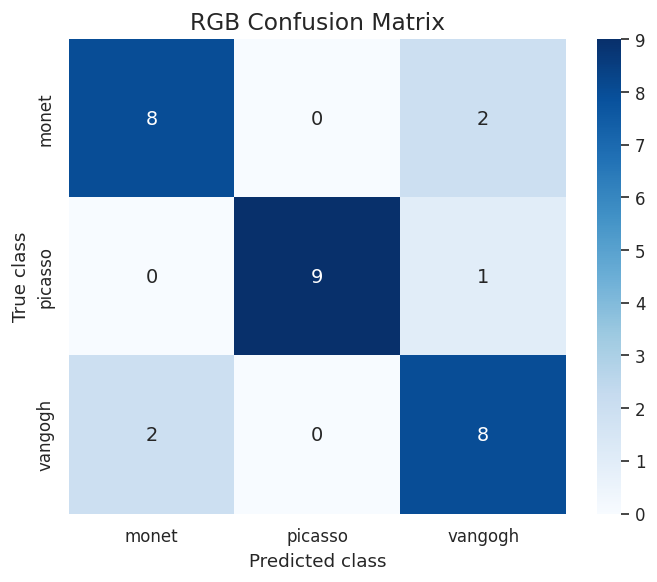

In [122]:
visualization.plot_confusion_matrix(
    confusion_matrix=rgb_results["confusion_matrix"],
    color_space="rgb",
    seed=42
)

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/confusion_matrix_rgb_seed42_normalized.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/confusion_matrix_rgb_seed42_normalized.pdf


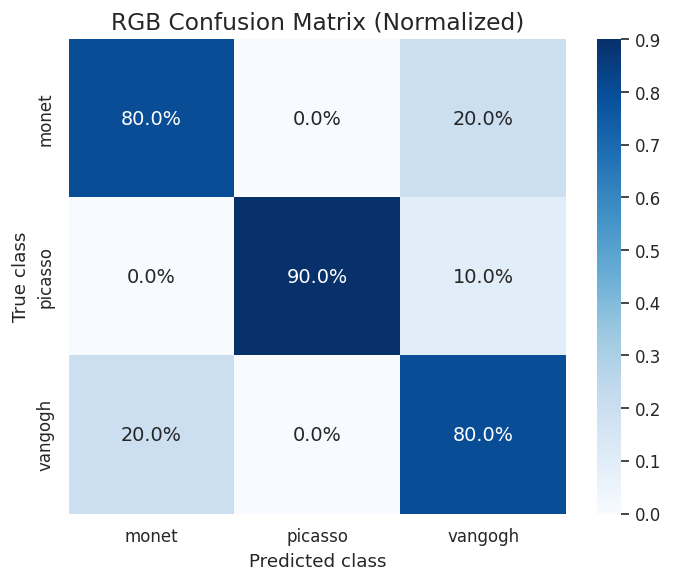

In [123]:
#Normalized confusion matrix
visualization.plot_confusion_matrix(
    confusion_matrix=rgb_results["confusion_matrix"],
    color_space="rgb",
    seed=42,
    normalize=True
)

### 11.6 Per-class performance

Precision, recall and F1-score provide complementary perspectives
on classification performance.

Precision describes how many predictions for a particular class
were correct.

Recall describes how many actual samples belonging to a class
were correctly identified.

F1-score provides a harmonic mean of precision and recall.

Comparing these metrics across artistic styles helps identify
whether the model performs consistently across all classes.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/class_metrics_rgb_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/class_metrics_rgb_seed42.pdf


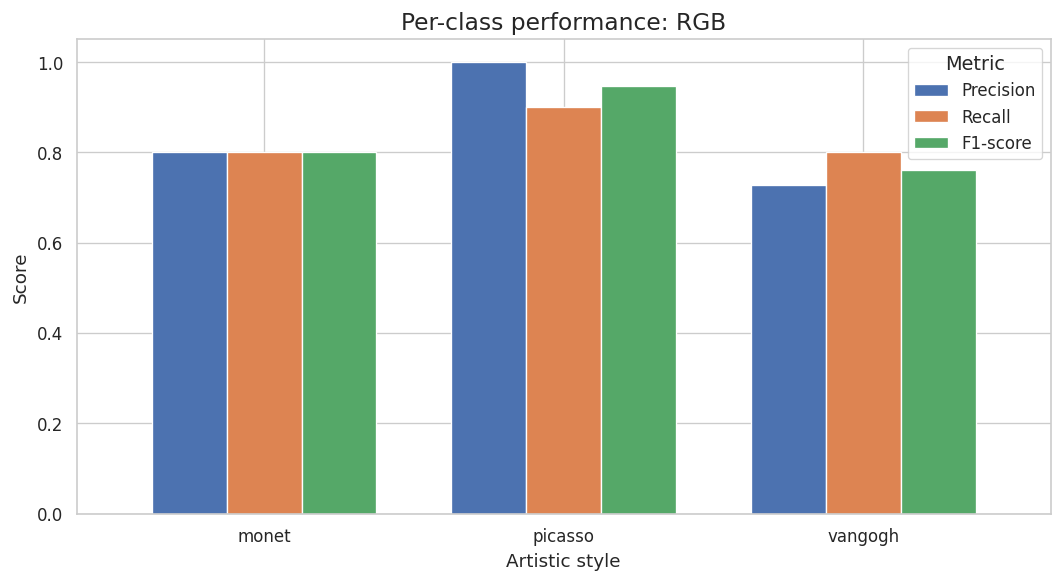

In [124]:
visualization.plot_class_metrics(
    class_report=rgb_results["class_report"],
    color_space="rgb",
    seed=42
)

### 11.7 Verify figure outputs

Verify that the generated figures have been saved successfully
in both the experiment output directory and the report directory.

PNG files are useful for general viewing, while PDF files preserve
vector-based figure elements for high-quality report inclusion.

In [125]:
print("Experiment figures:")

for path in sorted(config.FIGURES_DIR.glob("*rgb_seed42*")):
    print(path.name)

print("\nReport figures:")

for path in sorted(config.REPORT_FIGURES_DIR.glob("*rgb_seed42*")):
    print(path.name)

Experiment figures:
class_metrics_rgb_seed42.pdf
class_metrics_rgb_seed42.png
confusion_matrix_rgb_seed42.pdf
confusion_matrix_rgb_seed42.png
confusion_matrix_rgb_seed42_normalized.pdf
confusion_matrix_rgb_seed42_normalized.png
training_curves_rgb_seed42.pdf
training_curves_rgb_seed42.png

Report figures:
class_metrics_rgb_seed42.pdf
class_metrics_rgb_seed42.png
confusion_matrix_rgb_seed42.pdf
confusion_matrix_rgb_seed42.png
confusion_matrix_rgb_seed42_normalized.pdf
confusion_matrix_rgb_seed42_normalized.png
training_curves_rgb_seed42.pdf
training_curves_rgb_seed42.png


## 12. Experiment orchestration

This module provides a unified entry point for executing machine
learning experiments.

It connects the data loading, model training and evaluation modules
to ensure that experiments across different colour spaces follow
the same procedure.

The experiment runner also ensures that trained models, training
histories and evaluation results are saved consistently.

In [126]:
EXPERIMENT_MODULE_CONTENT = '''
from src import config
from src.data import load_datasets
from src.training import train_model
from src.evaluation import evaluate_model, save_evaluation_results


def run_experiment(color_space, seed=None, epochs=None):
    """
    Execute a complete CNN experiment for a selected colour space.

    Parameters
    ----------
    color_space : str
        Input colour representation: rgb, hsv or grayscale.

    seed : int, optional
        Random seed used for reproducibility.

    epochs : int, optional
        Maximum number of training epochs.

    Returns
    -------
    dict
        Model, training history, training metadata and evaluation results.
    """

    if color_space not in config.COLOR_SPACES:
        raise ValueError(
            f"Unsupported colour space: {color_space}. "
            f"Choose from {config.COLOR_SPACES}."
        )

    if seed is None:
        seed = config.DEFAULT_SEED

    print("=" * 60)
    print(f"Starting experiment: {color_space.upper()}")
    print(f"Random seed: {seed}")
    print("=" * 60)

    # Load datasets in the selected colour space.
    print("\\nLoading datasets...")

    train_dataset, validation_dataset, test_dataset = load_datasets(
        color_space=color_space,
        seed=seed
    )

    # Train the CNN.
    print("\\nTraining model...")

    model, history, training_metadata = train_model(
        train_dataset=train_dataset,
        validation_dataset=validation_dataset,
        color_space=color_space,
        seed=seed,
        epochs=epochs
    )

    # Evaluate the trained model.
    print("\\nEvaluating model...")

    evaluation_results = evaluate_model(
        model=model,
        test_dataset=test_dataset,
        color_space=color_space,
        seed=seed
    )

    # Save evaluation results.
    save_evaluation_results(
        results=evaluation_results,
        color_space=color_space,
        seed=seed
    )

    print("\\nExperiment completed.")
    print(f"Colour space: {color_space.upper()}")
    print(f"Seed: {seed}")
    print(f"Best epoch: {training_metadata['best_epoch']}")
    print(
        f"Test accuracy: "
        f"{evaluation_results['summary']['accuracy']:.4f}"
    )

    return {
        "color_space": color_space,
        "seed": seed,
        "model": model,
        "history": history,
        "training_metadata": training_metadata,
        "evaluation_results": evaluation_results
    }
'''

experiment_path = PROJECT_ROOT / "src" / "experiment.py"
experiment_path.write_text(EXPERIMENT_MODULE_CONTENT)

print(f"Created: {experiment_path}")

Created: /content/drive/MyDrive/DeepLearning/src/experiment.py


### 12.1 Import and verify the experiment module

Import the experiment runner and verify that it is available
for use in the individual experiment notebooks.

In [127]:
import importlib
from src import experiment

importlib.reload(experiment)

print("Experiment runner imported successfully.")

print("\nSupported colour spaces:")
print(config.COLOR_SPACES)

print("\nExperiment function:")
print(experiment.run_experiment)

Experiment runner imported successfully.

Supported colour spaces:
['rgb', 'hsv', 'grayscale']

Experiment function:
<function run_experiment at 0x7fc2f7d86980>


### 12.2 Verify experiment configuration

Check the configuration values that will be shared across all
colour-space experiments.

These settings should remain consistent to ensure that the
experiments differ only in their input colour representation,
unless a parameter is explicitly varied as part of the research design.

In [128]:
print("EXPERIMENT CONFIGURATION")
print("-" * 40)

print(f"Image size: {config.IMAGE_SIZE}")
print(f"Image channels: {config.IMAGE_CHANNELS}")
print(f"Batch size: {config.BATCH_SIZE}")
print(f"Maximum epochs: {config.MAX_EPOCHS}")
print(f"Learning rate: {config.LEARNING_RATE}")
print(f"Early stopping patience: {config.EARLY_STOPPING_PATIENCE}")
print(f"Dropout rate: {config.DROPOUT_RATE}")
print(f"Default random seed: {config.DEFAULT_SEED}")

print("\nColour spaces:")
for color_space in config.COLOR_SPACES:
    print(f"- {color_space}")

EXPERIMENT CONFIGURATION
----------------------------------------
Image size: (180, 180)
Image channels: 3
Batch size: 16
Maximum epochs: 30
Learning rate: 0.001
Early stopping patience: 6
Dropout rate: 0.4
Default random seed: 42

Colour spaces:
- rgb
- hsv
- grayscale


### 12.3 Verify output directories

Ensure that all directories required for storing experiment
outputs exist.

In [129]:
required_directories = [
    config.MODELS_DIR,
    config.METRICS_DIR,
    config.FIGURES_DIR,
    config.TABLES_DIR,
    config.LOGS_DIR,
    config.REPORT_FIGURES_DIR,
    config.REPORT_TABLES_DIR,
    config.REPORT_DRAFT_DIR
]

for directory in required_directories:
    directory.mkdir(parents=True, exist_ok=True)
    print(f"Verified: {directory.relative_to(PROJECT_ROOT)}")

Verified: outputs/models
Verified: outputs/metrics
Verified: outputs/figures
Verified: outputs/tables
Verified: outputs/logs
Verified: reports/figures
Verified: reports/tables
Verified: reports/draft


### 12.4 Verify saved experiment artefacts

Check that the existing RGB baseline model, training history
and evaluation results have been saved successfully.

In [130]:
rgb_artifacts = [
    config.MODELS_DIR / "rgb_seed42.keras",
    config.METRICS_DIR / "rgb_seed42_history.csv",
    config.METRICS_DIR / "rgb_seed42_evaluation.json",
    config.METRICS_DIR / "rgb_seed42_classification_report.csv",
    config.METRICS_DIR / "rgb_seed42_confusion_matrix.csv",
    config.METRICS_DIR / "rgb_seed42_predictions.csv",
]

for artifact in rgb_artifacts:
    status = "FOUND" if artifact.exists() else "MISSING"
    print(f"{status}: {artifact.name}")

FOUND: rgb_seed42.keras
FOUND: rgb_seed42_history.csv
FOUND: rgb_seed42_evaluation.json
FOUND: rgb_seed42_classification_report.csv
FOUND: rgb_seed42_confusion_matrix.csv
FOUND: rgb_seed42_predictions.csv


### 12.5 Verify saved evaluation results

Load the saved RGB evaluation metrics and inspect the results.

This confirms that the evaluation outputs can be accessed
independently of the original evaluation session.

In [131]:
import json

rgb_evaluation_path = (
    config.METRICS_DIR / "rgb_seed42_evaluation.json"
)

with open(rgb_evaluation_path, "r") as file:
    rgb_evaluation_summary = json.load(file)

print("RGB EVALUATION RESULTS")
print("-" * 40)

for metric, value in rgb_evaluation_summary.items():
    print(f"{metric}: {value}")

RGB EVALUATION RESULTS
----------------------------------------
color_space: rgb
seed: 42
accuracy: 0.8333333333333334
macro_precision: 0.8424242424242424
macro_recall: 0.8333333333333334
macro_f1: 0.8364243943191312
test_loss: 0.44609883427619934
test_accuracy: 0.8333333134651184


## 13. Environment and dependency management

This section documents the software environment used throughout
the project.

Recording Python and package versions helps improve reproducibility
and makes it easier to recreate the experimental environment.

### 13.1 Inspect the Python environment

Retrieve the Python version and the versions of the main libraries
used in the project.

In [132]:
import sys
import importlib.metadata as metadata

print("PYTHON ENVIRONMENT")
print("-" * 40)
print(f"Python version: {sys.version}")

packages = [
    "tensorflow",
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "seaborn",
    "Pillow"
]

print("\nINSTALLED PACKAGES")
print("-" * 40)

for package in packages:
    try:
        version = metadata.version(package)
        print(f"{package}: {version}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

PYTHON ENVIRONMENT
----------------------------------------
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

INSTALLED PACKAGES
----------------------------------------
tensorflow: 2.21.0
numpy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
matplotlib: 3.10.0
seaborn: 0.13.2
Pillow: 11.3.0


### 13.2 Generate requirements.txt

Create a requirements file containing the exact versions of the
main Python libraries used in the project.

The versions are retrieved directly from the current environment.

In [133]:
import sys
import importlib.metadata as metadata

from pathlib import Path

requirements = [
    "tensorflow",
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "seaborn",
    "Pillow"
]

requirements_lines = [
    f"# Python version: {sys.version.split()[0]}",
    "# Main project dependencies"
]

for package in requirements:
    try:
        version = metadata.version(package)
        requirements_lines.append(f"{package}=={version}")
    except metadata.PackageNotFoundError:
        print(f"Warning: {package} is not installed.")

requirements_path = PROJECT_ROOT / "requirements.txt"

requirements_path.write_text(
    "\n".join(requirements_lines) + "\n"
)

print("Created requirements.txt:")
print(requirements_path.read_text())

Created requirements.txt:
# Python version: 3.13.16
# Main project dependencies
tensorflow==2.21.0
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
Pillow==11.3.0



### 13.3 Verify project files

Check that the main project files have been created successfully.

In [134]:
project_files = [
    PROJECT_ROOT / "README.md",
    PROJECT_ROOT / "requirements.txt",
    PROJECT_ROOT / ".gitignore",
    config.SRC_DIR / "__init__.py",
    config.SRC_DIR / "config.py",
    config.SRC_DIR / "data.py",
    config.SRC_DIR / "models.py",
    config.SRC_DIR / "training.py",
    config.SRC_DIR / "evaluation.py",
    config.SRC_DIR / "visualization.py",
    config.SRC_DIR / "experiment.py"
]

print("PROJECT FILE VERIFICATION")
print("-" * 50)

for file_path in project_files:
    status = "FOUND" if file_path.exists() else "MISSING"
    print(f"{status}: {file_path.relative_to(PROJECT_ROOT)}")

PROJECT FILE VERIFICATION
--------------------------------------------------
FOUND: README.md
FOUND: requirements.txt
FOUND: .gitignore
FOUND: src/__init__.py
FOUND: src/config.py
FOUND: src/data.py
FOUND: src/models.py
FOUND: src/training.py
FOUND: src/evaluation.py
FOUND: src/visualization.py
FOUND: src/experiment.py


### 13.4 Inspect project documentation

Display the current README file to verify that it describes
the project and its structure accurately.

In [135]:
readme_path = PROJECT_ROOT / "README.md"

if readme_path.exists():
    print(readme_path.read_text())
else:
    print("README.md does not exist.")

# Beyond RGB: Artistic Style Classification

## Project overview

This project investigates how colour-space representation influences
the classification performance and generalisation of convolutional
neural networks when distinguishing between artistic styles.

## Research question

How does colour-space representation influence the classification
performance and generalisation of convolutional neural networks
when distinguishing between artistic styles?

## Dataset

The dataset contains paintings from three artistic styles:

- Monet
- Picasso
- Van Gogh

The experiments compare three image representations:

- RGB
- HSV
- Grayscale

## Experimental setup

A consistent CNN architecture and training configuration are used
to compare the colour-space representations.

## Project structure

- `data/`: Raw and processed datasets
- `notebooks/`: Jupyter notebooks for experiments and analysis
- `src/`: Reusable project source code
- `outputs/`: Models, metrics, figures, tables and logs
- `r